# 2.1. Разведочный анализ данных (EDA)

## 1. Загрузка и первичный осмотр

In [2]:
import pandas as pd
import gdown

In [4]:
url = 'https://drive.google.com/file/d/1f0wQLwjRL43pJf0ay0ElfJqc1ijFr5sn/view'
gdown.download(url, fuzzy=True)

Downloading...
From: https://drive.google.com/uc?id=1f0wQLwjRL43pJf0ay0ElfJqc1ijFr5sn
To: /content/retail_sales_mock_data.csv
100%|██████████| 1.09k/1.09k [00:00<00:00, 2.51MB/s]


'retail_sales_mock_data.csv'

In [5]:
df = pd.read_csv("retail_sales_mock_data.csv", parse_dates=["Date"], index_col="Date")
df.index.freq = "MS"
y = df["SalesAmount"].astype(float)

print(df.info())
display(df.head())
display(df.describe().T)
print("Пропуски:\n", df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48 entries, 2020-01-01 to 2023-12-01
Freq: MS
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   SalesAmount   48 non-null     int64
 1   Promotion     48 non-null     int64
 2   HolidayMonth  48 non-null     int64
dtypes: int64(3)
memory usage: 1.5 KB
None


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


,count,mean,std,min,25%,50%,75%,max
SalesAmount,48.0,11768.541667,2257.544863,7783.0,10219.75,11851.0,13014.0,17996.0
Promotion,48.0,0.125000,0.334219,0.0,0.00,0.0,0.0,1.0
HolidayMonth,48.0,0.083333,0.279310,0.0,0.00,0.0,0.0,1.0


Пропуски:
 SalesAmount     0
Promotion       0
HolidayMonth    0
dtype: int64


Ого, 48 значений, но хотя бы пропусков нет



## 2. Визуализации разных типов

In [6]:
import matplotlib.pyplot as plt

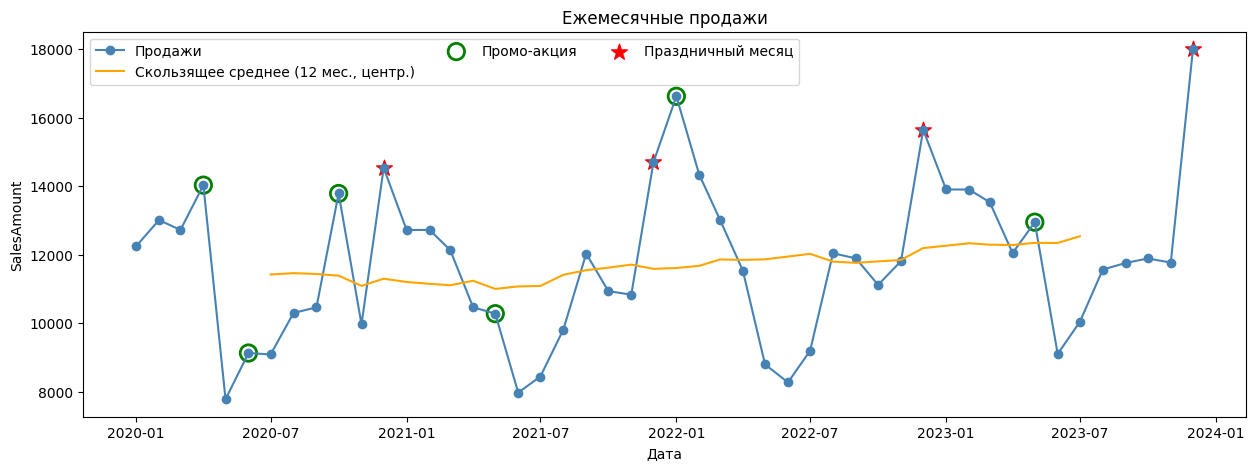

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y, marker="o", color="steelblue", label="Продажи")
ax.plot(y.rolling(12, center=True).mean(), color="orange", label="Скользящее среднее (12 мес., центр.)")
promo = y[df["Promotion"] == 1]
hol = y[df["HolidayMonth"] == 1]
ax.scatter(promo.index, promo, s=140, facecolors="none", edgecolors="green", lw=2, label="Промо-акция")
ax.scatter(hol.index, hol, s=140, marker="*", color="red", label="Праздничный месяц")
ax.set(title="Ежемесячные продажи", xlabel="Дата", ylabel="SalesAmount")
ax.legend(ncol=3)
plt.show()

- Попробовал использовать скользящее среднее за 12 месяцев, но линия тренда какая-то слишком прямая

- По поводу данных, в 2021-01 была какая-то мощная промо-акция, что побила рекорды по продажам в новогодние праздники

- 4 промо-акция не дала особого прироста

- Последний месяц на графике будто бы чуть выбивается, но допустим, что это были рекордные продажи в новогодний праздник, и не будем его убирать

In [10]:
import seaborn as sns
import calendar

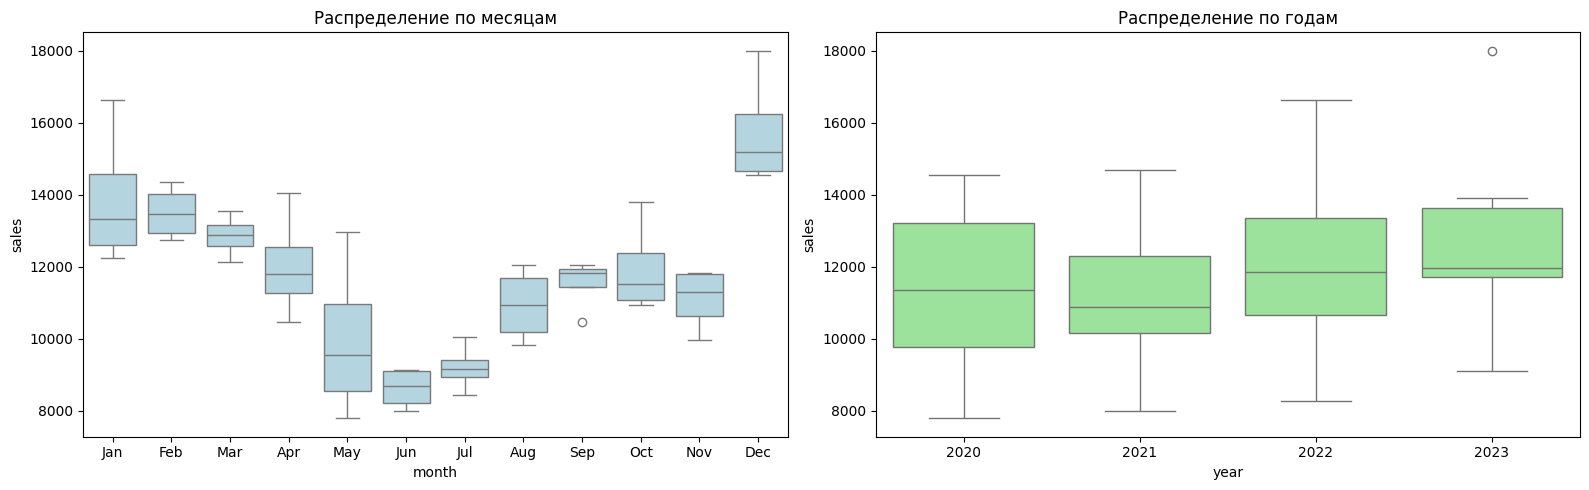

In [11]:
d = y.to_frame("sales")
d["year"], d["month"] = d.index.year, d.index.month

fig, axs = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=d, x="month", y="sales", ax=axs[0], color="lightblue")
axs[0].set_xticks(range(12))
axs[0].set_xticklabels(calendar.month_abbr[1:])
axs[0].set_title("Распределение по месяцам")

sns.boxplot(data=d, x="year", y="sales", ax=axs[1], color="lightgreen")
axs[1].set_title("Распределение по годам")

plt.tight_layout()
plt.show()

### Распределение по месяцам
 - По медиане на декабрь приходится большой объем продаж, а в июне - самый низкий
 - Между ноябрем и декабрем большой разрыв по продажам, тогда как у других боксплотов разница плавная
 - В марте, июне, июле, сентябре и... в феврале (возможно) коробочки довольно узкие и довольно предсказуемы
 - В сентябре какое-то значение аномальное (какой-то один год, так как всего значений по 4 штуки)
 - Широкие коробки в январе, мае и в декабре
 - Май какой-то самый непредсказуемый месяц из-за больших усов и широкой коробки
 - В январе были какие-то невероятные продажи, как раз та самая промо-акция побившая продажи новогоднего месяца (верхний ус большой)
 - На июнь и июль приходятся самые минимальные продажи, а осенью начинается разогрев
 - В сентябре большая часть значений сгруппирована наверху (ассиметрия)

 ### Распределение по годам
 - Нижние усы показывают, что в основном продажи растут
 - В 2021 году в среднем продажи упали, но дальше восстановились, но можно все равно сказать, что продажи растут
 - В 2023 году выброс
 - В 2022 году большой размах
 - В 2021 и, особенно, в 2023 ассиметрия, другие довольно симметричные (тут про зеленые коробки)   

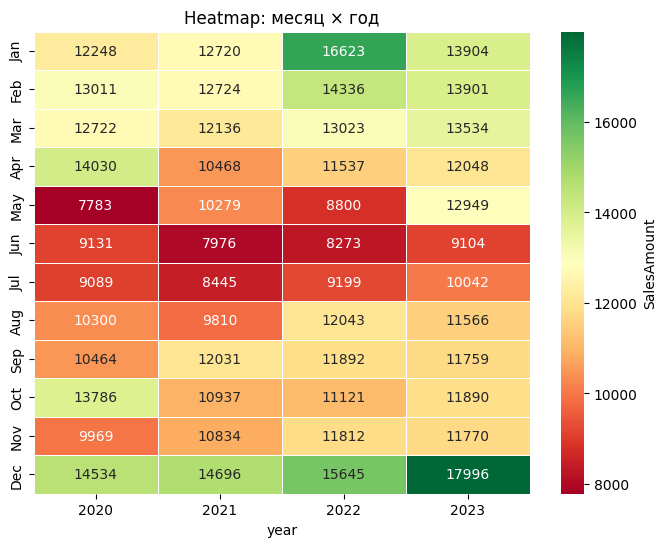

In [12]:
pivot = d.pivot_table(values="sales", index="month", columns="year")
pivot.index = calendar.month_abbr[1:]
plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", linewidths=.5, cbar_kws={"label": "SalesAmount"})
plt.title("Heatmap: месяц × год"); plt.show()

- Как говорилось раньше, промо-акция в январе 2022 побила рекорд по продажам января 2021, и возможно она произвела фурор, так как продажи остались высокими и в феврале  
- Июнь и июль (возможно и май, кроме 2023) красные, провальные месяца по продажам, а декабрь - успешные
- Вроде все равно каждый год суммарные годовые продажи растут
- Октябрь и апрель 2022 года оказались успешным по продажам, чем в соответствующие месяца следующих лет
- Особо не видно, но правая часть с каждым годом "зеленеет" (мб этот пункт пересекается с третьим)
- В мае 2021 нетипично большие продажи по сравнению с 2020 и 2023, но дальше компенсировалось низкими продажами в следующем месяце, также с октябрем и ноябрем 2020

In [13]:
import numpy as np

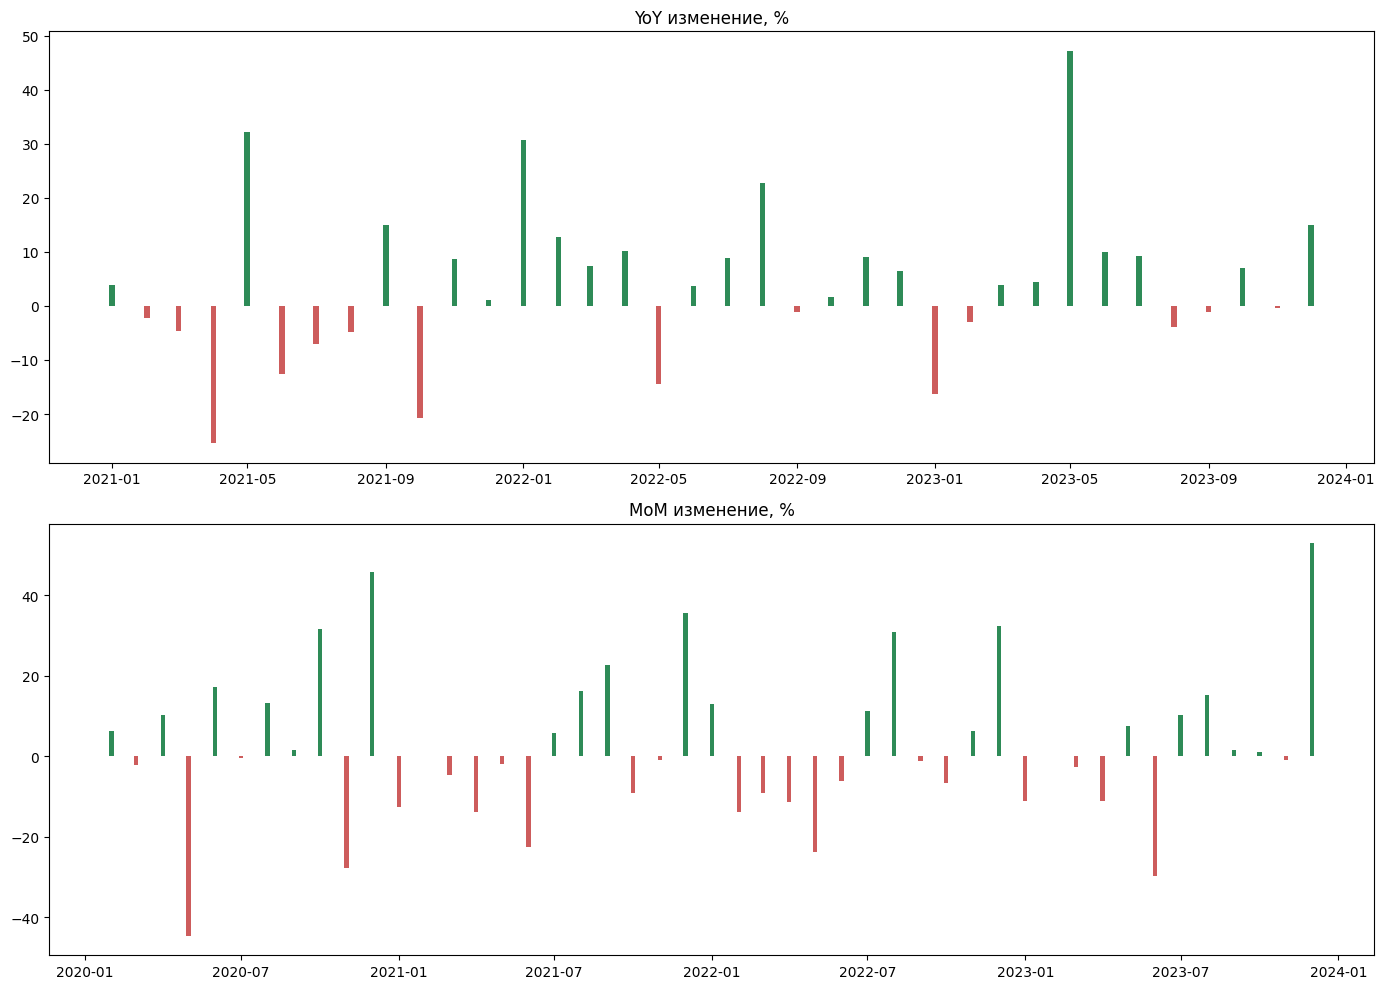

In [14]:
fig, axs = plt.subplots(2, 1, figsize=(14, 10))

yoy = y.pct_change(12) * 100
axs[0].bar(yoy.index, yoy.values, width=5, color=np.where(yoy >= 0, "seagreen", "indianred"))
axs[0].set_title("YoY изменение, %")

mom = y.pct_change() * 100
axs[1].bar(mom.index, mom.values, width=5, color=np.where(mom >= 0, "seagreen", "indianred"))
axs[1].set_title("MoM изменение, %")
plt.tight_layout(); plt.show()

### Годовые изменения (YoY)
- 2021
    1. колебания без явного направления, они есть и большие, но постоянно друг друга гасят, хотя больше преобладают просадки
    2. самый большой изменение в отрицательную сторону либо, что-то было нетипично низкое, либо это что-то нетипично высокое (хитмапа сверху подтверждает второе)
    3. декабрь-февраль примерно такие же, как в прошлом году
- 2022
    1. почти все месяцы в плюсе, хотя больше половины показывают колебания в пределах 10 процентов
    2. просадок только в мае около 15 процентов
- 2023
    1. Предыдущий январь был намного лучше по продажам, чем этот, но зато в мае прирост около 47 процентов
    2. тут тоже в основном каждый месяц прирост по сравнению с предыдущим годом

### Месячные изменения (MoM)
- декабрь 2023 самый большой прирост по сравнению с ноябрем 2023, а в мае 2020 самое большое падение
- перед самым большим приростом 3 месяца количество продаж было почти таким же
- в 2020 в среднем каждый месяц скачки большие, другие года более стабльные
- с января 2021 года по май 2021 стабильное падение продаж
- каждый год декабрь самый прибильный по приросту



## 3. Декомпозиция ряда
### 3.1 Аддитивная, мультипликативная и STL декомпозиции

Для месячных данных берем период равный 12

In [16]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

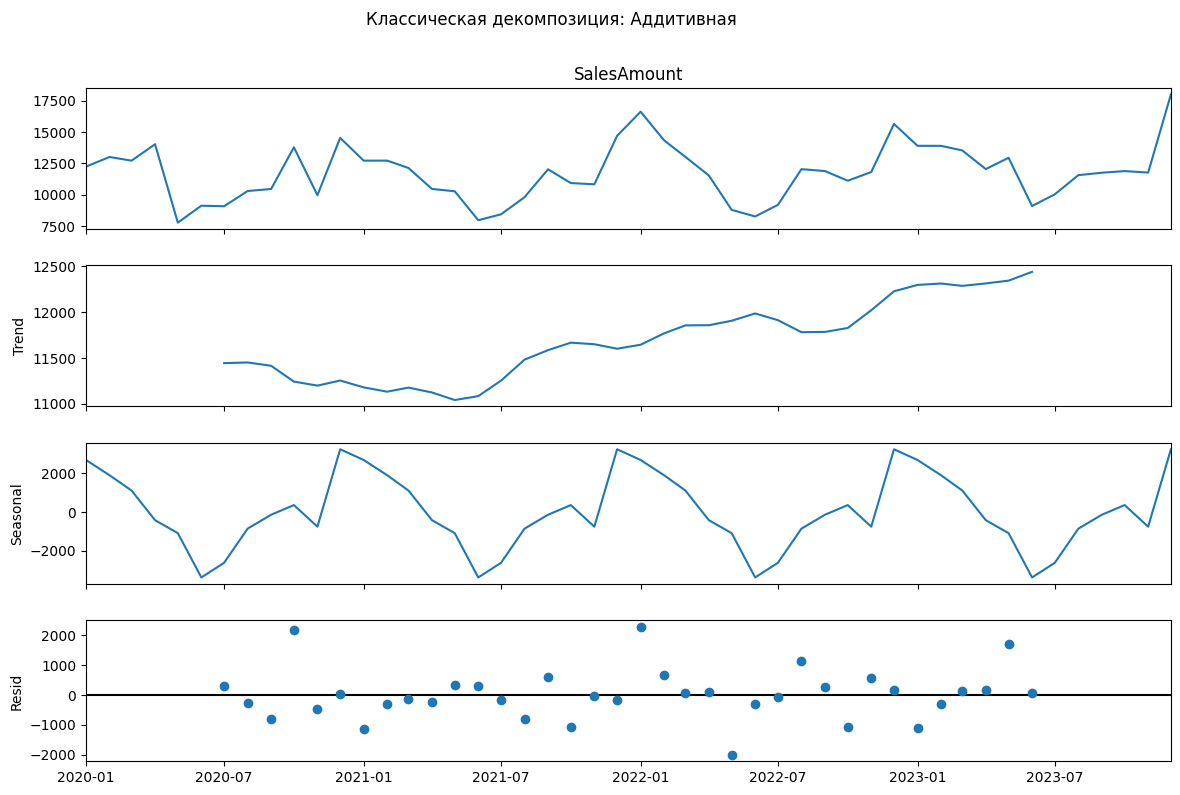

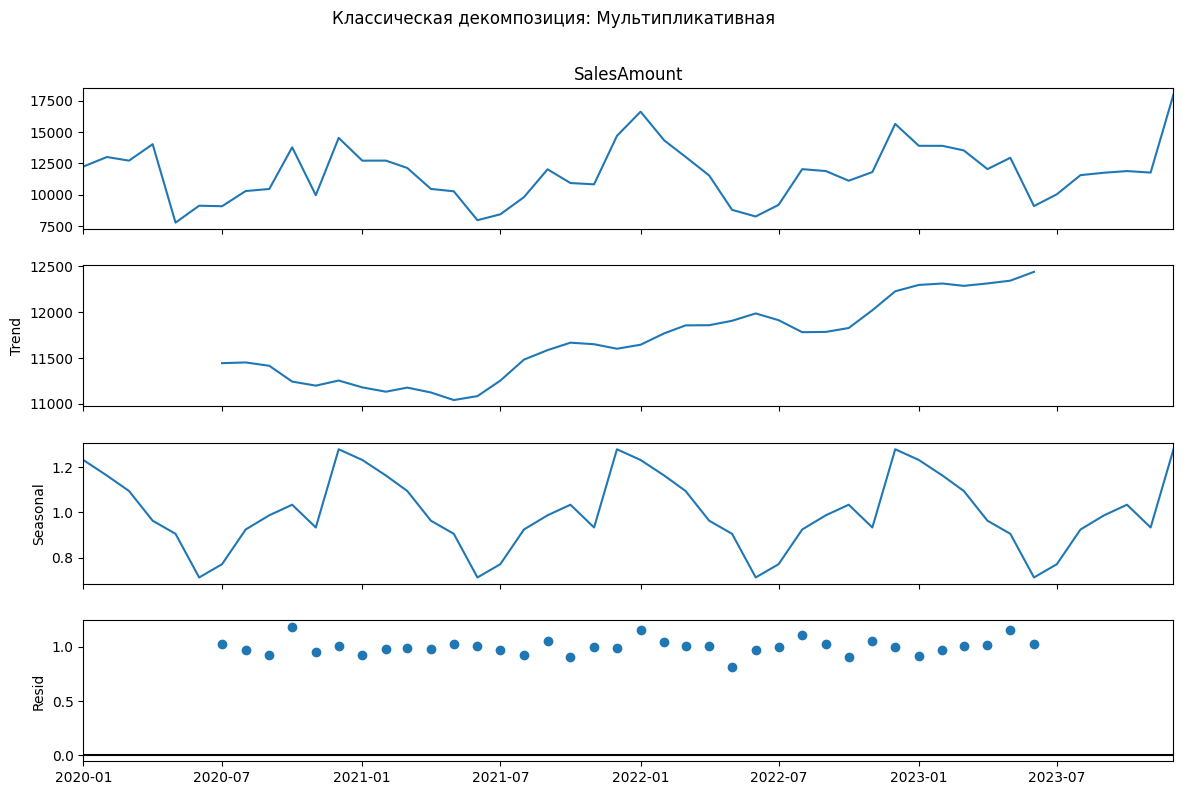

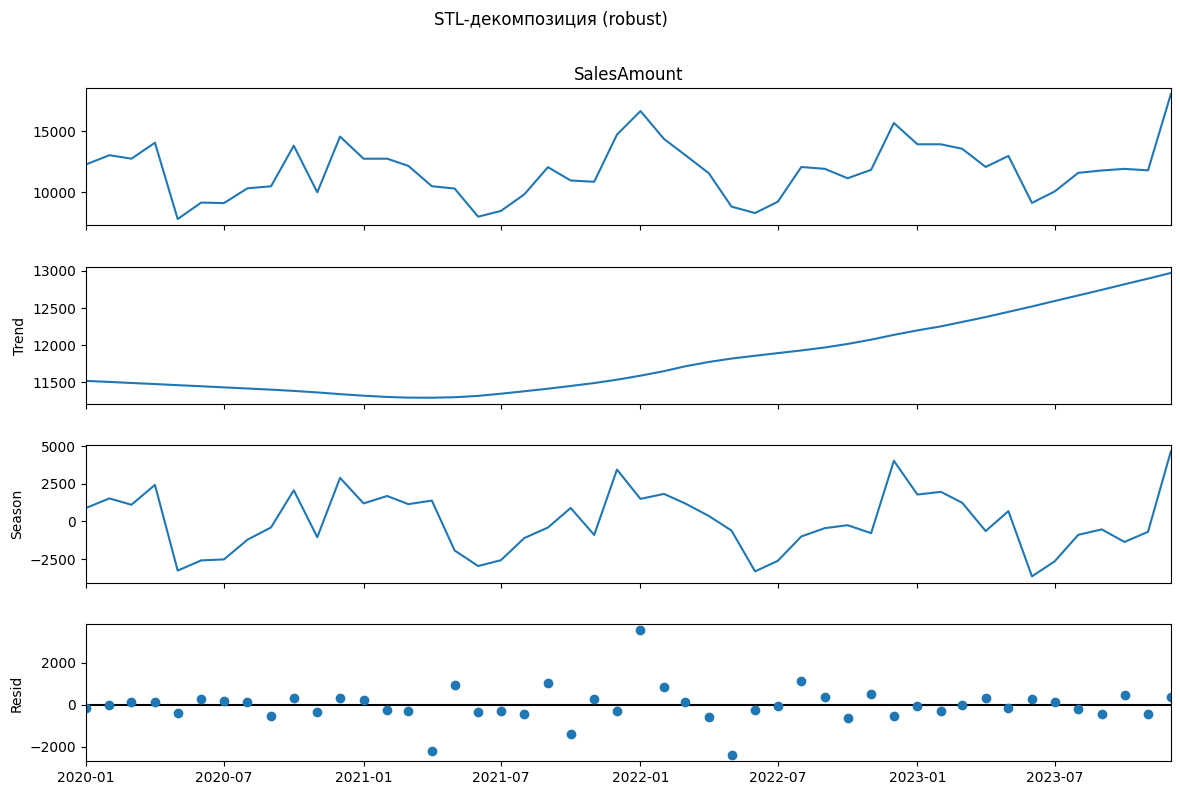

In [17]:
P = 12

dec_add = seasonal_decompose(y, model="additive", period=P)
dec_mul = seasonal_decompose(y, model="multiplicative", period=P)
stl = STL(y, period=P, seasonal=13, robust=True).fit()

for name, res in [("Аддитивная", dec_add), ("Мультипликативная", dec_mul)]:
    fig = res.plot()
    fig.set_size_inches(13, 8)
    fig.suptitle(f"Классическая декомпозиция: {name}", y=1.02)
    plt.show()

fig = stl.plot()
fig.set_size_inches(13, 8)
fig.suptitle("STL-декомпозиция (robust)", y=1.02); plt.show()

- Аддитивная модель
    1. Остатки нормально не распределены, так же имеются выбросы (3 точки вверху и 1 снизу), возможно, модель не справилась с ростом амплитуды продаж (хотя там рост довольно слабый)
    2. Остатки в диапазоне примерно от -2000 до 2100 (на графике особо не видно)
    3. Так же прослеживается какая-то сезонность в остатках хотя ее быть не должно
    4. Тренд срезал 6 месяцев по бокам
    5. Сезонность переодичная, но зубчатая (из-за малого количества данных)
- Мульпликатиная
    1. Тренд по направелению такой же, как у аддитивной
    2. Такая же сезонность по направелению
    3. Остатки центрированы около единицы, выглядит более кучнее (хотя возможно из-за масштаба)
    4. Так же имеются некоторые выбросы в остатках
- STL
    1. Тренд сохранён в каждом месяце, но как-то подозрительно плавный, хотя общая логика, которая была выявлена ранее, прослеживается (продажи упали в 2021, дальше начали расти)
    2. На графике сезонности так же прослеживается периодичность, но она не постоянная
    3. Остатки по краям находятся близко к нулю, а в середине нчинаются снова колебания
    4. Диапазон остатков от -2300 до 2700
    5. Меньше выбросов, чем у аддитивной

### 3.2 Спектральный анализ (FFT)

Для начала проверим стационарный ли ряд по тесту Дики-Фуллера и KPSS, так как fft плохо работает с нестационарными рядами

In [18]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

In [19]:
adf_stat, adf_p, _, _, adf_crit, _ = adfuller(y, autolag="AIC", result_object=False)
kpss_stat, kpss_p, _, kpss_crit = kpss(y, regression="c", nlags="auto", result_object=False)

stationarity_results = pd.DataFrame({
    "Метрика теста": [adf_stat, kpss_stat],
    "p-value": [adf_p, kpss_p],
    "Критическое значение (5%)": [adf_crit["5%"], kpss_crit["5%"]],
    "Результат": [
        "Стационарен (H0 отвергнута)" if adf_p < 0.05 else "Нестационарен (H0 принята)",
        "Стационарен (H0 принята)" if kpss_p > 0.05 else "Нестационарен (H0 отвергнута)"
    ]
}, index=["ADF тест", "KPSS тест"])

display(stationarity_results.round(4))

print(f"ADF-тест (H0: ряд нестационарен, содержит единичный корень):")
if adf_p < 0.05:
    print(f"  -> p-value ({adf_p:.4f}) < 0.05. Нулевая гипотеза отвергается. РЯД СТАЦИОНАРЕН.")
else:
    print(f"  -> p-value ({adf_p:.4f}) >= 0.05. Нулевая гипотеза НЕ отвергается. РЯД НЕСТАЦИОНАРЕН.")

print(f"\nKPSS-тест (H0: ряд стационарен вокруг константы или тренда):")
if kpss_p > 0.05:
    print(f"  -> p-value ({kpss_p:.4f}) > 0.05. Нулевая гипотеза НЕ отвергается. РЯД СТАЦИОНАРЕН.")
else:
    print(f"  -> p-value ({kpss_p:.4f}) <= 0.05. Нулевая гипотеза отвергается. РЯД НЕСТАЦИОНАРЕН.")

/tmp/ipykernel_617/4027332265.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, kpss_crit = kpss(y, regression="c", nlags="auto", result_object=False)


,Метрика теста,p-value,Критическое значение (5%),Результат
ADF тест,-4.5142,0.0002,-2.9333,Стационарен (H0 отвергнута)
KPSS тест,0.1388,0.1000,0.4630,Стационарен (H0 принята)


ADF-тест (H0: ряд нестационарен, содержит единичный корень):
  -> p-value (0.0002) < 0.05. Нулевая гипотеза отвергается. РЯД СТАЦИОНАРЕН.

KPSS-тест (H0: ряд стационарен вокруг константы или тренда):
  -> p-value (0.1000) > 0.05. Нулевая гипотеза НЕ отвергается. РЯД СТАЦИОНАРЕН.


Ряд стационарный поэтому можно и без обойтись без detrend

In [20]:
from scipy.signal import windows
from scipy.fft import fft, fftfreq
import pywt

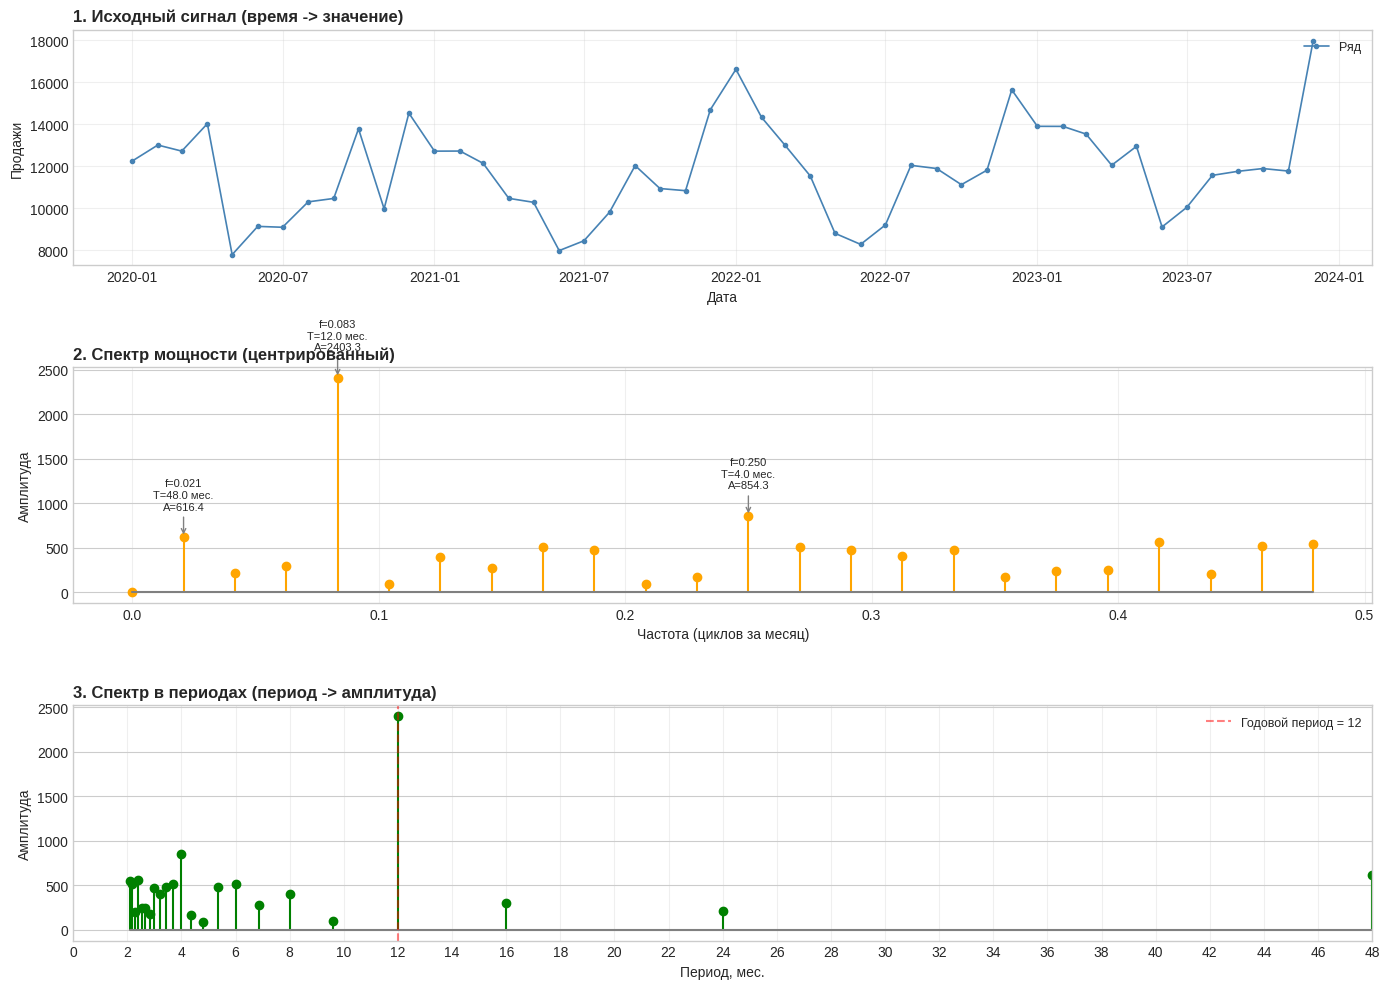

Результаты Фурье-анализа:
Частота    Период (мес)    Амплитуда 
----------------------------------------
0.0833     12.0            2403.27   
0.2500     4.0             854.34    
0.0208     48.0            616.44    


In [21]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fft, fftfreq

plt.style.use('seaborn-v0_8-whitegrid')

signal_raw = y.values
signal_mean = np.mean(signal_raw)
signal = signal_raw - signal_mean

dt = 1.0
N = len(signal)
t = np.arange(N) * dt

fft_values = fft(signal)
frequencies = fftfreq(N, dt)

power = (2.0 / N) * np.abs(fft_values[:N // 2])
freqs = frequencies[:N // 2]

fig, axs = plt.subplots(3, 1, figsize=(14, 10))

axs[0].plot(y.index, signal_raw, color='steelblue', linewidth=1.2, marker='o', markersize=3, label='Ряд')
axs[0].set_title('1. Исходный сигнал (время -> значение)', fontweight='bold', loc='left')
axs[0].set_xlabel('Дата')
axs[0].set_ylabel('Продажи')
axs[0].legend(loc='upper right', fontsize=9)
axs[0].grid(True, alpha=0.3)

axs[1].stem(freqs, power, linefmt='orange', markerfmt='o', basefmt='gray')
axs[1].set_title('2. Спектр мощности (центрированный)', fontweight='bold', loc='left')
axs[1].set_xlabel('Частота (циклов за месяц)')
axs[1].set_ylabel('Амплитуда')
axs[1].grid(True, alpha=0.3, axis='x')

valid_mask = freqs > 0
top_indices = np.argsort(power[valid_mask])[-3:][::-1]
top_freqs = freqs[valid_mask][top_indices]

for f in top_freqs:
    period = 1 / f
    amp = power[freqs == f][0]
    label = f'f={f:.3f}\nT={period:.1f} мес.\nA={amp:.1f}'
    axs[1].annotate(label, xy=(f, amp), xytext=(0, 20), textcoords='offset points',
                    fontsize=8, ha='center',
                    arrowprops=dict(arrowstyle='->', color='gray'))

periods = 1 / freqs[valid_mask]
power_filtered = power[valid_mask]

axs[2].stem(periods, power_filtered, linefmt='green', markerfmt='o', basefmt='gray')
axs[2].set_title('3. Спектр в периодах (период -> амплитуда)', fontweight='bold', loc='left')
axs[2].set_xlabel('Период, мес.')
axs[2].set_ylabel('Амплитуда')
axs[2].set_xlim(0, 48)
axs[2].set_xticks(np.arange(0, 49, 2))
axs[2].grid(True, alpha=0.3, axis='x')

axs[2].axvline(x=12, color='red', linestyle='--', alpha=0.5, label='Годовой период = 12')
axs[2].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

print("Результаты Фурье-анализа:")
print(f"{'Частота':<10} {'Период (мес)':<15} {'Амплитуда':<10}")
print("-" * 40)

for idx in np.argsort(power[1:])[::-1][:3] + 1:
    f = freqs[idx]
    amp = power[idx]
    period = 1 / f if f > 0 else np.inf
    print(f"{f:<10.4f} {period:<15.1f} {amp:<10.2f}")

- Самым значимым периодом по fft стало число 12, т.е годовая сезонность, и также выделяется 4-месячная гармоника

- Тут также есть спектральные утечки, но они особо не влияют на эти два упомянутых, так как они четко просматриваются. Возможно они повлияли на полугодовую сезонность так-как 5 и 6 чуть похожи

- Прослеживается, 48 месячная гармоника, что странно, так как данных всего 48, поэтому думаю, ее учитывать в данном ряду не нужно



### 3.3 Вейвлет-анализ

In [22]:
from matplotlib.gridspec import GridSpec

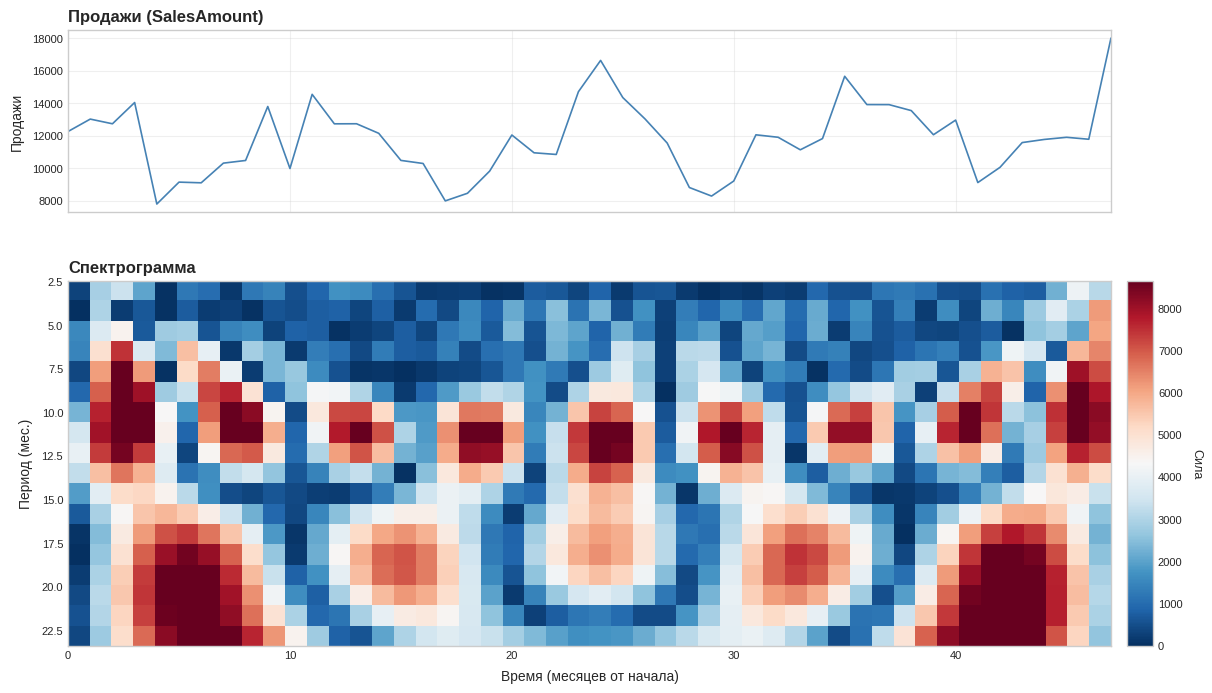

In [23]:
signal = y.values
t = np.arange(len(signal))
sampling_period = 1

wavelet = "morl"
scales = np.arange(1, 25)
coefficients, frequencies = pywt.cwt(signal, scales, wavelet, sampling_period=sampling_period)

mask = frequencies > 0
periods = 1 / frequencies[mask]
coefficients_abs = np.abs(coefficients[mask, :])
period_mask = (periods >= 2) & (periods <= 24)
periods_plot = periods[period_mask]
coefficients_plot = coefficients_abs[period_mask, :]

fig = plt.figure(figsize=(14, 8))
gs = GridSpec(2, 2, height_ratios=[1, 2], width_ratios=[40, 1], hspace=0.25, wspace=0.03)

ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[1, 0], sharex=ax0)
cax = fig.add_subplot(gs[1, 1])

ax0.plot(t, signal, color='steelblue', linewidth=1.2)
ax0.set_title('Продажи (SalesAmount)', fontweight='bold', loc='left', pad=6)
ax0.set_ylabel('Продажи', labelpad=6)
ax0.grid(True, alpha=0.3)
ax0.tick_params(labelsize=8)
plt.setp(ax0.get_xticklabels(), visible=False)

im = ax1.imshow(coefficients_plot,
                extent=[t.min(), t.max(), periods_plot.max(), periods_plot.min()],
                aspect='auto', cmap='RdBu_r',
                vmin=0, vmax=np.percentile(coefficients_plot, 95))

ax1.set_title('Спектрограмма', fontweight='bold', loc='left', pad=6)
ax1.set_ylabel('Период (мес.)', labelpad=6)
ax1.set_xlabel('Время (месяцев от начала)', labelpad=6)
ax1.tick_params(labelsize=8)
ax1.grid(False)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Сила', rotation=270, labelpad=14, fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.show()

wavelet_results = {
    "t": t,
    "frequencies": frequencies[mask],
    "periods": periods,
    "coefficients": coefficients_abs,
    "period_mask": period_mask,
}

- Годовая сезонность (10–13 месяцев)
  1. Главная движущая сила ряда, идет через все 4 года почти равномерно
- Долгосрочный цикл (18–22 месяца)
  1. Начинается с мощного всплеска в первые 3–8 месяцев (темно-красный массив внизу), но вроде по краям вейвлет преобразование всегда по краям дает такие результаты
  2. В середине есть слабо-красные пятна, повторяющегося цикла в этом периоде особо нет в данном промежутке времени
- Высокочастотные шумы (до 5 месяцев)
  1. На протяжении почти всего ряда слабо чередуется (из-за этой мозайки) синий и светло-синий или темно-синий и синий цвета

In [24]:
def find_dominant_cycles(periods, coefficients, top_n=5, min_distance=1):
    mean_power = np.mean(coefficients, axis=1)
    top_idx = np.argsort(mean_power)[::-1]
    results = []
    for idx in top_idx:
        if len(results) >= top_n:
            break
        period = periods[idx]
        if not any(abs(period - r) < min_distance for r in results):
            results.append(round(period, 1))
    return results

dominant_cycles = find_dominant_cycles(periods_plot, coefficients_plot, top_n=5, min_distance=1)

print("Важные циклы в данных (месяцев):")
for i, period in enumerate(dominant_cycles, 1):
    print(f"  {i}. ~{period} мес.")

Важные циклы в данных (месяцев):
  1. ~11.1 мес.
  2. ~9.8 мес.
  3. ~12.3 мес.
  4. ~19.7 мес.
  5. ~18.5 мес.


Первые 3 как-то похожи на 12 месяц, поэтому их можно схлопнуть в 12

А вот последние как-то неожиданно появлись, я тут ожидал увидеть что-то около 4-ого месяца

### 3.4 Сравнение методов на основе спектрального анализа и декомпозиции

В соответствии с проведенным анализом:
- **Классическая декомпозиция** выявила базовую структуру ряда, однако привела к потере 12 краевых точек (по 6 с каждой стороны). Простота этого метода была в том, что мне нужно было указать один параметр P = 12. У мультипликативной остатки имеют меньше разброс, чем у аддитивной. Всё остальное у них будто одинаковое. Не думаю, что этот метод хорошо подходит к данному ряду (мультипликативная лучше аддитивной чуть)
- **STL** сохранила все точки тренда ряда, но тренд подозрительно плавный. Сезонность более изменчивая, чем у классической декомпозиции. Остатки хоть и ближе к нулю по краям, но потом в середине всплеск.
- **FFT** четко подтвердило доминирующий годовой цикл с периодом T = 12 месяцев (амплитуда  2403.27), а также выявило субгармонику на 4 месяце. Но он не показал в каком момент времени происходило, а просто схлопнул всё в одну конкретную частоту.
- **Вейвлет-преобразование** наглядно продемонстрировал, что годовой цикл (локализованный в районе 10–13 месяцев) является главной движущей силой и стабильно сохраняет свою интенсивность на протяжении всех 4 лет измерений. Так же выделил долгосрочный цикл, который не отображлся в FFT/

# 2.2. Построение прогнозных моделей

In [25]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

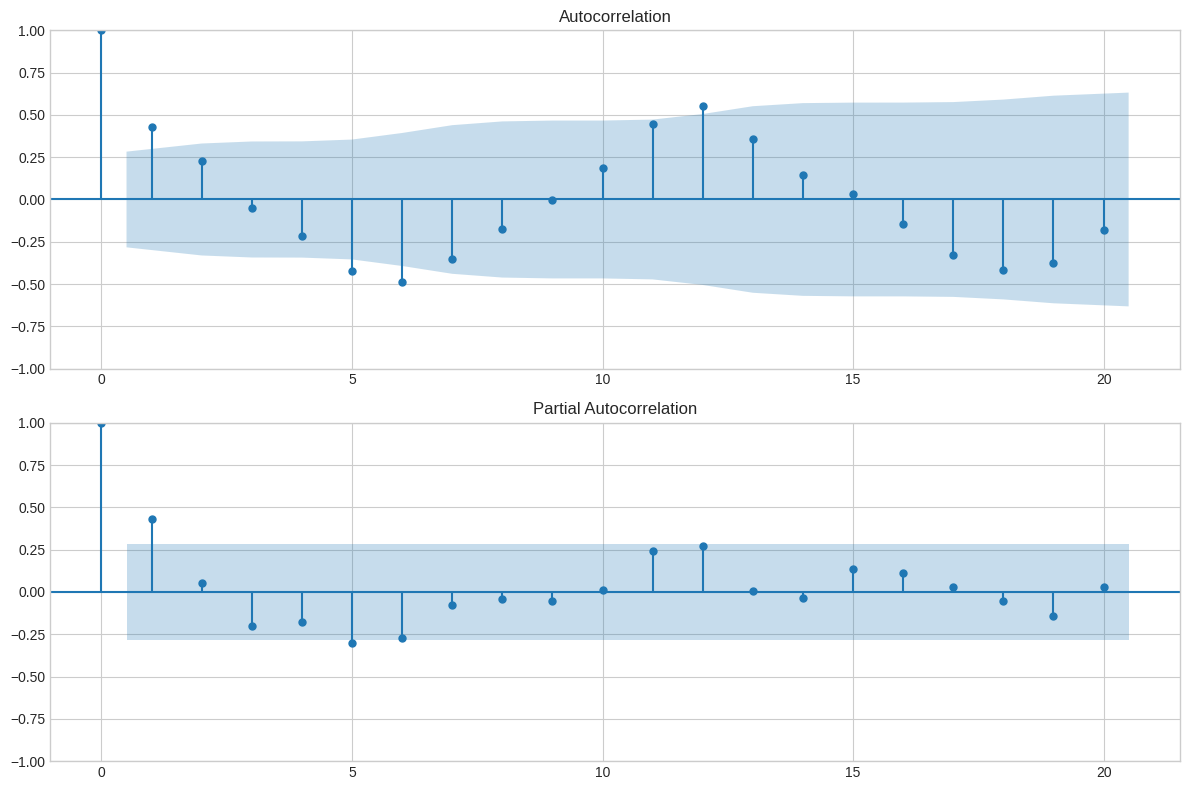

In [26]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df["SalesAmount"], lags=20, ax=ax1)
plot_pacf(df["SalesAmount"], lags=20, ax=ax2)

plt.tight_layout()
plt.show()

Последний значимый лаг частичной автокоррелиации вроде бы 12, хоть там почти на грани

## 1. Train/test-разбиение

Train: 2020-01-01 .. 2022-12-01  (n=36)
Test : 2023-01-01 .. 2023-12-01  (n=12)


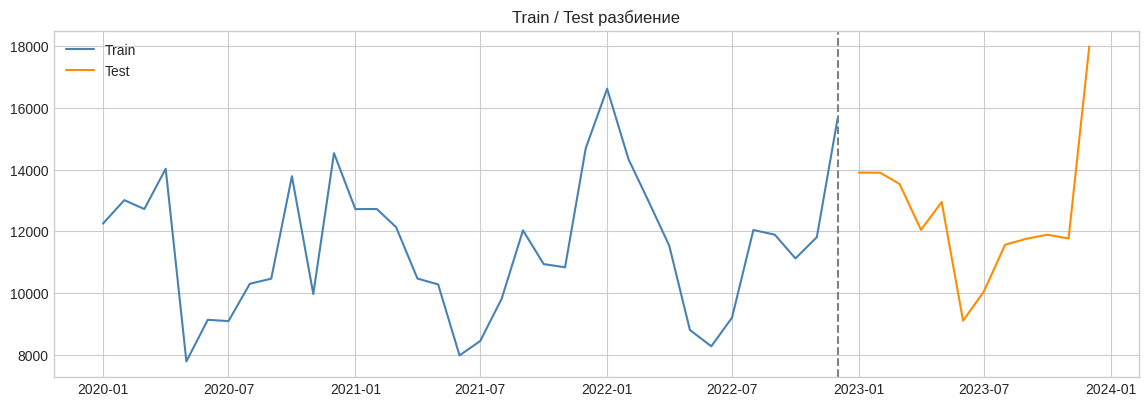

In [27]:
h = 12
y_train, y_test = y.iloc[:-h], y.iloc[-h:]
exog_all = df[["Promotion", "HolidayMonth"]].astype(float)
exog_train, exog_test = exog_all.iloc[:-h], exog_all.iloc[-h:]

print(f"Train: {y_train.index[0].date()} .. {y_train.index[-1].date()}  (n={len(y_train)})")
print(f"Test : {y_test.index[0].date()} .. {y_test.index[-1].date()}  (n={len(y_test)})")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y_train, label="Train", color="steelblue")
ax.plot(y_test, label="Test", color="darkorange")
ax.axvline(y_train.index[-1], color="gray", ls="--")
ax.legend(); ax.set_title("Train / Test разбиение"); plt.show()

## 2. Подбор параметров

Из EDA: ряд стационарен по тестам, доминирующий период - это 12 месяцев, HolidayMonth статистически значим (декабрьский пик).
Отсюда ARIMA(p,d,q) без сезонной части как базовая модель без учёта годового цикла и SARIMAX(p,d,q)(P,D,Q,12) с экзогенным HolidayMonth (буду использовать, как основную).

Параметры подбираем комбинированно: auto_arima + ручная проверка сеткой по AIC/BIC на train.

In [28]:
!pip install pmdarima


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 12.2 MB/s eta 0:00:00


In [29]:
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from itertools import product

In [30]:
auto_nonseasonal = auto_arima(
    y_train, start_p=0, max_p=12, start_q=0, max_q=12, d=None,
    seasonal=False, trace=True, stepwise=True,
    error_action="ignore", suppress_warnings=True
)
print("auto_arima (несезонная) предлагает ARIMA:", auto_nonseasonal.order)

rows = []
for p, d, q in product(range(12, 13), range(0, 2), range(12, 13)):
    try:
        m = ARIMA(y_train, order=(p, d, q)).fit()
        rows.append((p, d, q, m.aic, m.bic))
    except Exception:
        pass
grid_arima = pd.DataFrame(rows, columns=["p", "d", "q", "AIC", "BIC"]).sort_values("AIC")
display(grid_arima.head(10).reset_index(drop=True))
best_arima_order = tuple(grid_arima.iloc[0][["p", "d", "q"]].astype(int))
print("Лучший по AIC (сетка):", best_arima_order)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=778.739, Time=0.11 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=664.123, Time=0.07 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=744.544, Time=0.44 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.79 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=664.726, Time=0.82 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=665.549, Time=4.95 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=653.040, Time=0.10 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=660.355, Time=0.08 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=655.042, Time=0.50 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=655.105, Time=0.59 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=655.621, Time=1.39 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=656.320, Time=2.83 sec

Best model:  ARIMA(1,0,0)(0,0,0)[0] intercept
Total fit time: 12.751 seconds
auto_arima (несезонная) предлагает ARIMA: (1, 0, 0)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,p,d,q,AIC,BIC
0,12,1,12,667.853336,706.737038
1,12,0,12,681.974897,723.146389


Лучший по AIC (сетка): (12, 1, 12)


d тут ожидалось 0, так как ряд стационнарный и ничего дифференцировать не нужно было, интересно получилось... Возможно слабый тренд всё же влияет

In [31]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

Ограничиваем сезонные кандидаты P, Q <= 1  при n_train=36 и m=12 модели с P или Q = 2 не имеют достаточно наблюдений для устойчивой оценки.

In [32]:
auto_seasonal = auto_arima(
    y_train, exogenous=exog_train[["HolidayMonth"]],
    start_p=0, max_p=2, start_q=0, max_q=2, d=None,
    start_P=0, max_P=1, start_Q=0, max_Q=1, D=None, max_D=1, m=12,
    seasonal=True, trace=True, stepwise=True,
    error_action="ignore", suppress_warnings=True
)
print("auto_arima (сезонная + HolidayMonth) предлагает SARIMAX:", auto_seasonal.order, auto_seasonal.seasonal_order)

cand_orders = {auto_seasonal.order, (1, 1, 1), (1, 0, 1), (0, 1, 1)}
cand_seasonal = {auto_seasonal.seasonal_order, (1, 0, 0, 12), (0, 0, 1, 12),
                  (1, 1, 0, 12), (0, 1, 1, 12), (1, 0, 1, 12)}

rows = []
for order in cand_orders:
    for sorder in cand_seasonal:
        try:
            m = SARIMAX(y_train, exog=exog_train[["HolidayMonth"]], order=order,
                        seasonal_order=sorder, enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
            rows.append((order, sorder, m.aic, m.bic))
        except Exception:
            pass
grid_sarimax = pd.DataFrame(rows, columns=["order", "seasonal_order", "AIC", "BIC"]).sort_values("AIC")
display(grid_sarimax.reset_index(drop=True))
best_sarimax_order, best_sarimax_sorder = grid_sarimax.iloc[0][["order", "seasonal_order"]]
print("Лучшая по AIC:", best_sarimax_order, best_sarimax_sorder)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=425.761, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=426.130, Time=1.13 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=425.628, Time=1.27 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=424.616, Time=0.11 sec
 ARIMA(0,0,0)(1,1,0)[12] intercept   : AIC=424.339, Time=0.44 sec
 ARIMA(0,0,0)(1,1,1)[12] intercept   : AIC=inf, Time=1.97 sec
 ARIMA(0,0,0)(0,1,1)[12] intercept   : AIC=424.613, Time=0.18 sec
 ARIMA(0,0,1)(1,1,0)[12] intercept   : AIC=425.311, Time=0.14 sec
 ARIMA(1,0,1)(1,1,0)[12] intercept   : AIC=inf, Time=0.46 sec
 ARIMA(0,0,0)(1,1,0)[12]             : AIC=425.114, Time=0.04 sec

Best model:  ARIMA(0,0,0)(1,1,0)[12] intercept
Total fit time: 5.814 seconds
auto_arima (сезонная + HolidayMonth) предлагает SARIMAX: (0, 0, 0) (1, 1, 0, 12)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for v

,order,seasonal_order,AIC,BIC
0,"(0, 1, 1)","(0, 1, 1, 12)",156.023779,156.812677
1,"(1, 1, 1)","(0, 1, 1, 12)",157.966160,158.952283
2,"(1, 1, 1)","(1, 1, 0, 12)",174.387554,175.900479
3,"(1, 0, 1)","(0, 1, 1, 12)",179.124795,180.637720
4,"(0, 1, 1)","(1, 1, 0, 12)",188.650097,190.241678
5,"(1, 0, 1)","(1, 1, 0, 12)",188.771909,190.761385
6,"(0, 0, 0)","(0, 1, 1, 12)",191.212843,192.406529
7,"(0, 0, 0)","(1, 1, 0, 12)",215.750937,217.205657
8,"(1, 1, 1)","(1, 0, 1, 12)",368.476402,374.743537
9,"(0, 1, 1)","(1, 0, 1, 12)",374.749409,379.972021


Лучшая по AIC: (0, 1, 1) (0, 1, 1, 12)


|Параметр|Интерпретация|
|---|---|
|$p=0$|Нет прямой зависимости от продаж 1 месяц назад|
|$d=1$|Есть слабый, но устойчивый растущий тренд, его нужно убрать обычным дифференцированием (опять же странно)|
|$q=1$|Ошибка прогноза прошлого месяца важна|
|$P=0$|Нет прямой зависимости от значения ровно год назад|
|$D=1$|Нужно убрать сезонность дифференцированием|
|$Q=1$|Ошибка прогноза в месяце прошлого года влияет на прогноз этого месяца|
|$s=12$|Годовая сезонность (месячные данные)|

In [33]:
model_arima = ARIMA(y_train, order=best_arima_order).fit()
model_sarimax = SARIMAX(y_train, exog=exog_train[["HolidayMonth"]], order=tuple(best_sarimax_order),
                         seasonal_order=tuple(best_sarimax_sorder),
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

print(model_arima.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


                               SARIMAX Results                                
Dep. Variable:            SalesAmount   No. Observations:                   36
Model:               ARIMA(12, 1, 12)   Log Likelihood                -308.927
Date:                Sun, 04 Oct 2026   AIC                            667.853
Time:                        18:14:20   BIC                            706.737
Sample:                    01-01-2020   HQIC                           681.276
                         - 12-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2168      4.621     -0.047      0.963      -9.273       8.840
ar.L2         -0.0963      5.235     -0.018      0.985     -10.357      10.164
ar.L3         -0.1213      4.722     -0.026      0.9

In [34]:
print(model_sarimax.summary())

                                     SARIMAX Results                                      
Dep. Variable:                        SalesAmount   No. Observations:                   36
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 -74.012
Date:                            Sun, 04 Oct 2026   AIC                            156.024
Time:                                    18:14:20   BIC                            156.813
Sample:                                01-01-2020   HQIC                           154.321
                                     - 12-01-2022                                         
Covariance Type:                              opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
HolidayMonth     1.9849   4.34e+04   4.57e-05      1.000   -8.51e+04    8.51e+04
ma.L1           -1.0243      

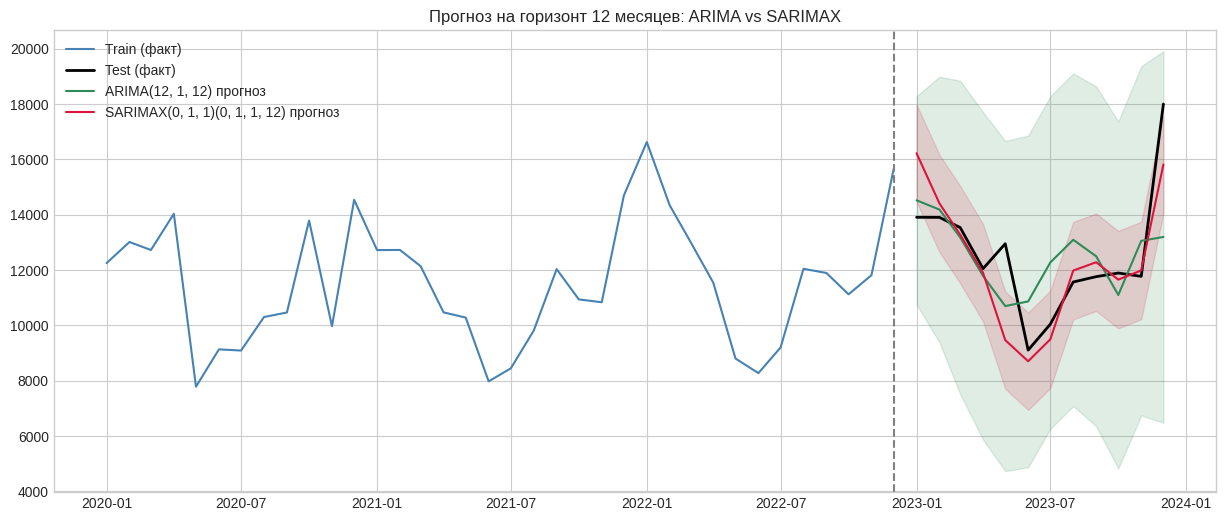

In [35]:
fc_arima = model_arima.get_forecast(steps=h)
fc_sarimax = model_sarimax.get_forecast(steps=h, exog=exog_test[["HolidayMonth"]])

pred_arima = fc_arima.predicted_mean
ci_arima = fc_arima.conf_int(alpha=0.05)
pred_sarimax = fc_sarimax.predicted_mean
ci_sarimax = fc_sarimax.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(y_train, label="Train (факт)", color="steelblue")
ax.plot(y_test, label="Test (факт)", color="black", lw=2)

ax.plot(y_test.index, pred_arima, label=f"ARIMA{best_arima_order} прогноз", color="seagreen")
ax.fill_between(y_test.index, ci_arima.iloc[:, 0], ci_arima.iloc[:, 1], color="seagreen", alpha=0.15)

ax.plot(y_test.index, pred_sarimax, label=f"SARIMAX{tuple(best_sarimax_order)}{tuple(best_sarimax_sorder)} прогноз", color="crimson")
ax.fill_between(y_test.index, ci_sarimax.iloc[:, 0], ci_sarimax.iloc[:, 1], color="crimson", alpha=0.15)

ax.axvline(y_train.index[-1], color="gray", ls="--")
ax.legend(); ax.set_title("Прогноз на горизонт 12 месяцев: ARIMA vs SARIMAX"); plt.show()

Из графиков можно сказать, что SARIMA с экзогенными справляется лучше, и диапазон возможных значений у нее меньше по сравнению с ARIMA, у которой нижний диапазон в какие-то экстремальные значения заходит, которые не наблюдались раньше. SARIMA не предсказала всплеск в районе 5 месяца 2023. Скорее всего это хорошо, так как можно сказать, что модель не переобучилась (хотя данных тут всего 36 на обучение было)

### Максимально возможный горизонт

Горизонт теста выше ограничен длиной отложенной выборки (12 мес.). Чтобы показать, насколько далеко вперёд модель ещё держит приемлемое качество, дополнительно строим прогноз за пределы имеющихся данных (24 месяца).

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


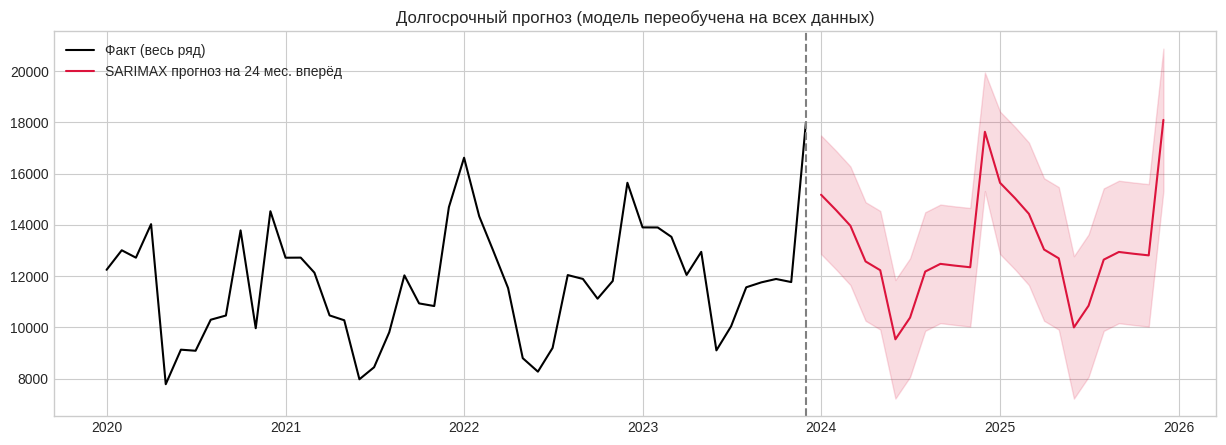

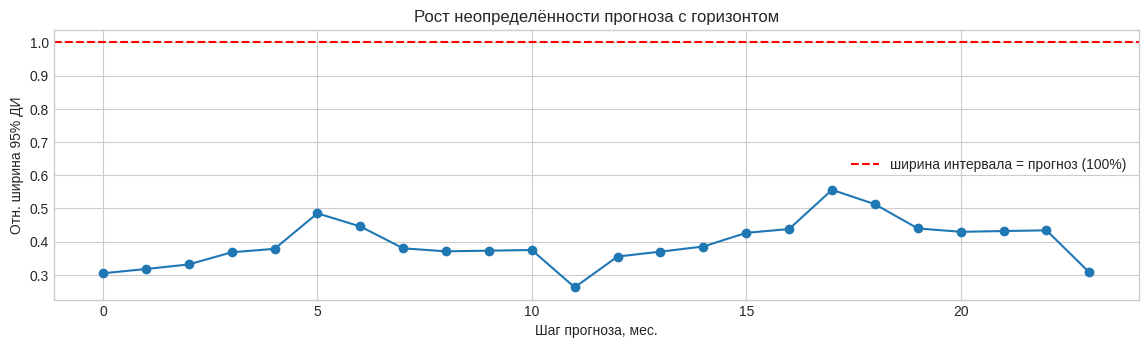

Приемлемое качество (ширина 95% ДИ ≤ 100% прогноза) сохраняется примерно до 24-го месяца вперёд.


In [36]:
h_long = 24
model_sarimax_full = SARIMAX(y, exog=exog_all[["HolidayMonth"]], order=tuple(best_sarimax_order),
                              seasonal_order=tuple(best_sarimax_sorder),
                              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=h_long, freq="MS")
exog_future = pd.DataFrame({"HolidayMonth": (future_idx.month == 12).astype(float)}, index=future_idx)

fc_long = model_sarimax_full.get_forecast(steps=h_long, exog=exog_future)
pred_long = fc_long.predicted_mean
ci_long = fc_long.conf_int(alpha=0.05)
rel_width = (ci_long.iloc[:, 1] - ci_long.iloc[:, 0]) / pred_long

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y, label="Факт (весь ряд)", color="black")
ax.plot(pred_long.index, pred_long, label="SARIMAX прогноз на 24 мес. вперёд", color="crimson")
ax.fill_between(pred_long.index, ci_long.iloc[:, 0], ci_long.iloc[:, 1], color="crimson", alpha=0.15)
ax.axvline(y.index[-1], color="gray", ls="--")
ax.legend(); ax.set_title("Долгосрочный прогноз (модель переобучена на всех данных)"); plt.show()

plt.figure(figsize=(14, 3.5))
plt.plot(rel_width.values, marker="o")
plt.axhline(1.0, color="red", ls="--", label="ширина интервала = прогноз (100%)")
plt.xlabel("Шаг прогноза, мес."); plt.ylabel("Отн. ширина 95% ДИ"); plt.legend()
plt.title("Рост неопределённости прогноза с горизонтом"); plt.show()

acceptable = rel_width[rel_width <= 1.0]
print(f"Приемлемое качество (ширина 95% ДИ ≤ 100% прогноза) сохраняется примерно до {len(acceptable)}-го месяца вперёд.")

В принципе похоже на правду

## 4. Метрики качества прогноза (MSE, R²) на тестовой выборке

In [37]:
from sklearn.metrics import mean_squared_error, r2_score

,MSE,RMSE,MAE,"MAPE, %",R²
Модель,,,,,
"ARIMA(12, 1, 12)",3500004.752,1870.830,1408.209,11.159,0.243
"SARIMAX(0, 1, 1)(0, 1, 1, 12)",1966987.205,1402.493,935.215,7.008,0.575


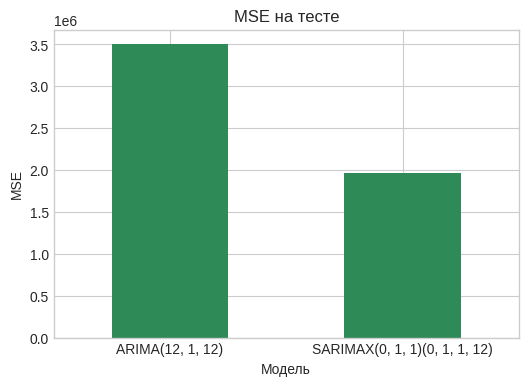

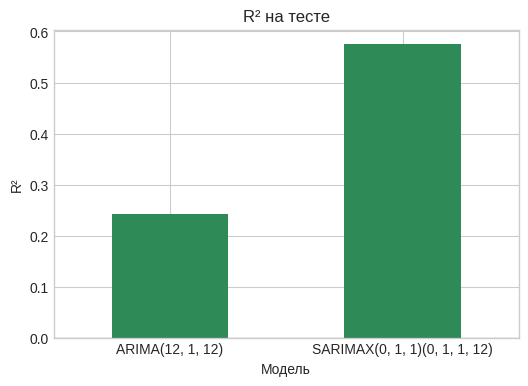

In [38]:
def metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return {"Модель": name, "MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE, %": mape, "R²": r2}

metrics_tab = pd.DataFrame([
    metrics(y_test, pred_arima, f"ARIMA{best_arima_order}"),
    metrics(y_test, pred_sarimax, f"SARIMAX{tuple(best_sarimax_order)}{tuple(best_sarimax_sorder)}"),
]).set_index("Модель").round(3)
display(metrics_tab)

metrics_tab[["MSE"]].plot(kind="bar", figsize=(6, 4), legend=False, color=["seagreen", "crimson"])
plt.title("MSE на тесте"); plt.ylabel("MSE"); plt.xticks(rotation=0); plt.show()

metrics_tab[["R²"]].plot(kind="bar", figsize=(6, 4), legend=False, color=["seagreen", "crimson"])
plt.title("R² на тесте"); plt.ylabel("R²"); plt.axhline(0, color="k", lw=.8); plt.xticks(rotation=0); plt.show()

SARIMA превоходит ARIMA по все параметрам. $R^2$ у первой больше в 2 раза, а ошибка по MSE в 1.8 раз ниже.



## 5. Сравнение по информационным критериям AIC / BIC (на train)

,AIC,BIC,Log-likelihood,Параметров
Модель,,,,
"ARIMA(12, 1, 12)",667.85,706.74,-308.93,25
"SARIMAX(0, 1, 1)(0, 1, 1, 12)",156.02,156.81,-74.01,4


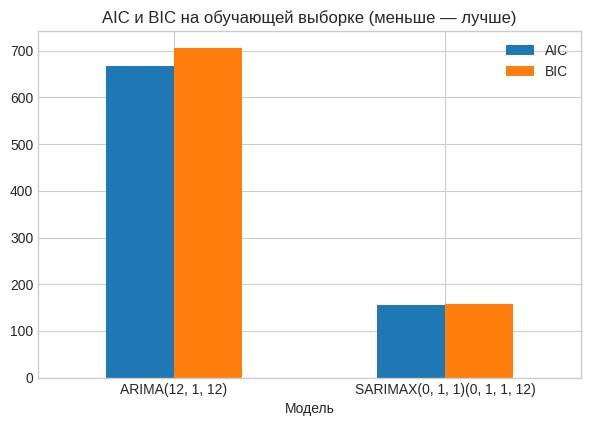

In [39]:
ic_tab = pd.DataFrame([
    {"Модель": f"ARIMA{best_arima_order}", "AIC": model_arima.aic, "BIC": model_arima.bic,
     "Log-likelihood": model_arima.llf, "Параметров": len(model_arima.params)},
    {"Модель": f"SARIMAX{tuple(best_sarimax_order)}{tuple(best_sarimax_sorder)}",
     "AIC": model_sarimax.aic, "BIC": model_sarimax.bic,
     "Log-likelihood": model_sarimax.llf, "Параметров": len(model_sarimax.params)},
]).set_index("Модель").round(2)
display(ic_tab)

ic_tab[["AIC", "BIC"]].plot(kind="bar", figsize=(7, 4.5))
plt.title("AIC и BIC на обучающей выборке (меньше — лучше)"); plt.xticks(rotation=0); plt.show()

Тут уже ощутимый разрыв модель SARIMA легче почти в 5 раз, а качество метрик заметно лучше.

## 6. Анализ остатков
### 6.1 Нормальность, автокорреляция, гомоскедастичность — табличная сводка

In [42]:
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, het_arch

In [43]:
def resid_diagnostics(model, name):
    burn = getattr(model, "loglikelihood_burn", 0) or 0
    resid = model.resid.iloc[burn:].dropna()
    n = len(resid)

    # 1. Нормальность
    shapiro_p = stats.shapiro(resid)[1]
    jb_p = stats.jarque_bera(resid)[1]

    # 2. Автокорреляция (тест Льюнга-Бокса)
    lb_lag = max(1, min(12, n // 2 - 1))
    lb_p = acorr_ljungbox(resid, lags=[lb_lag], return_df=True)["lb_pvalue"].iloc[0]

    # 3. Гомоскедастичность (тест Бройша-Пагана)
    exog_bp = sm.add_constant(np.arange(n))
    bp_stat, bp_p, _, _ = het_breuschpagan(resid.values, exog_bp)

    return {
        "Модель": name,
        "Shapiro-Wilk p (норм.)": shapiro_p,
        "Jarque-Bera p (норм.)": jb_p,
        "Ljung-Box p (автокорр.)": lb_p,
        "Breusch-Pagan p (гомоскед.)": bp_p,
        "n остатков": n,
    }

diag_tab = pd.DataFrame([
    resid_diagnostics(model_arima, f"ARIMA{best_arima_order}"),
    resid_diagnostics(model_sarimax, f"SARIMAX{tuple(best_sarimax_order)}{tuple(best_sarimax_sorder)}"),
]).set_index("Модель").round(4)
display(diag_tab)

alpha = 0.05
for name, row in diag_tab.iterrows():
    print(f"\n{'='*60}")
    print(f"Модель: {name}  (n остатков = {int(row['n остатков'])})")
    print(f"{'='*60}")

    # Нормальность (Shapiro-Wilk)
    if row["Shapiro-Wilk p (норм.)"] > alpha:
        print(f"Shapiro-Wilk p = {row['Shapiro-Wilk p (норм.)']:.4f} > 0.05  "
              f"-> ТЕСТ ПРОЙДЕН: остатки распределены нормально")
    else:
        print(f"Shapiro-Wilk p = {row['Shapiro-Wilk p (норм.)']:.4f} <= 0.05  "
              f"-> ТЕСТ НЕ ПРОЙДЕН: распределение остатков отличается от нормального")

    # Нормальность (Jarque-Bera)
    if row["Jarque-Bera p (норм.)"] > alpha:
        print(f"Jarque-Bera p  = {row['Jarque-Bera p (норм.)']:.4f} > 0.05  "
              f"-> ТЕСТ ПРОЙДЕН: нет оснований отвергать нормальность")
    else:
        print(f"Jarque-Bera p  = {row['Jarque-Bera p (норм.)']:.4f} <= 0.05  "
              f"-> ТЕСТ НЕ ПРОЙДЕН: распределение остатков не нормально")

    # Автокорреляция (Ljung-Box)
    if row["Ljung-Box p (автокорр.)"] > alpha:
        print(f"Ljung-Box p    = {row['Ljung-Box p (автокорр.)']:.4f} > 0.05  "
              f"-> ТЕСТ ПРОЙДЕН: автокорреляция в остатках не обнаружена")
    else:
        print(f"Ljung-Box p    = {row['Ljung-Box p (автокорр.)']:.4f} <= 0.05  "
              f"-> ТЕСТ НЕ ПРОЙДЕН: обнаружена автокорреляция остатков")

    # Гомоскедастичность (Breusch-Pagan)
    if row["Breusch-Pagan p (гомоскед.)"] > alpha:
        print(f"Breusch-Pagan p= {row['Breusch-Pagan p (гомоскед.)']:.4f} > 0.05  "
              f"-> ТЕСТ ПРОЙДЕН: дисперсия остатков постоянна (гомоскедастичность)")
    else:
        print(f"Breusch-Pagan p= {row['Breusch-Pagan p (гомоскед.)']:.4f} <= 0.05  "
              f"-> ТЕСТ НЕ ПРОЙДЕН: обнаружена гетероскедастичность")

,Shapiro-Wilk p (норм.),Jarque-Bera p (норм.),Ljung-Box p (автокорр.),Breusch-Pagan p (гомоскед.),n остатков
Модель,,,,,
"ARIMA(12, 1, 12)",0.7420,0.8713,0.1380,0.0863,35
"SARIMAX(0, 1, 1)(0, 1, 1, 12)",0.9563,0.9214,0.2466,0.9933,9



Модель: ARIMA(12, 1, 12)  (n остатков = 35)
Shapiro-Wilk p = 0.7420 > 0.05  -> ТЕСТ ПРОЙДЕН: остатки распределены нормально
Jarque-Bera p  = 0.8713 > 0.05  -> ТЕСТ ПРОЙДЕН: нет оснований отвергать нормальность
Ljung-Box p    = 0.1380 > 0.05  -> ТЕСТ ПРОЙДЕН: автокорреляция в остатках не обнаружена
Breusch-Pagan p= 0.0863 > 0.05  -> ТЕСТ ПРОЙДЕН: дисперсия остатков постоянна (гомоскедастичность)

Модель: SARIMAX(0, 1, 1)(0, 1, 1, 12)  (n остатков = 9)
Shapiro-Wilk p = 0.9563 > 0.05  -> ТЕСТ ПРОЙДЕН: остатки распределены нормально
Jarque-Bera p  = 0.9214 > 0.05  -> ТЕСТ ПРОЙДЕН: нет оснований отвергать нормальность
Ljung-Box p    = 0.2466 > 0.05  -> ТЕСТ ПРОЙДЕН: автокорреляция в остатках не обнаружена
Breusch-Pagan p= 0.9933 > 0.05  -> ТЕСТ ПРОЙДЕН: дисперсия остатков постоянна (гомоскедастичность)


Формально все тесты о обоих моделей пройдены, и остатки не отличимы от белого шума, но у SARIMAX ставятся под сомнение тесты, так как остатков всего 9, что довольно мало, но на проверке качества метрик и визуально SARIMA справляется

### 6.2 Графический анализ остатков

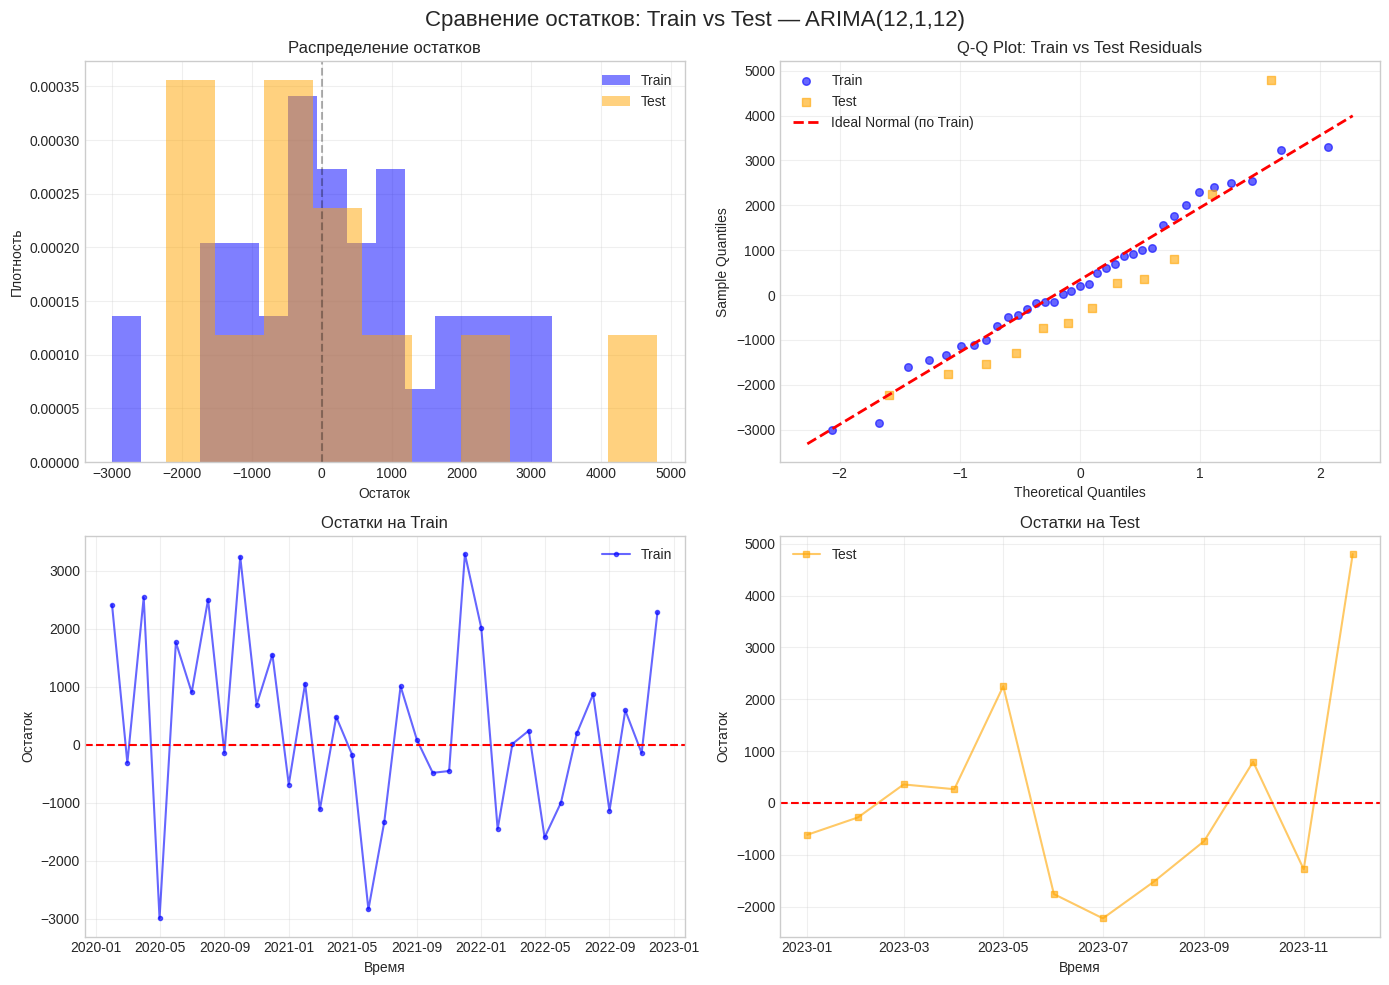

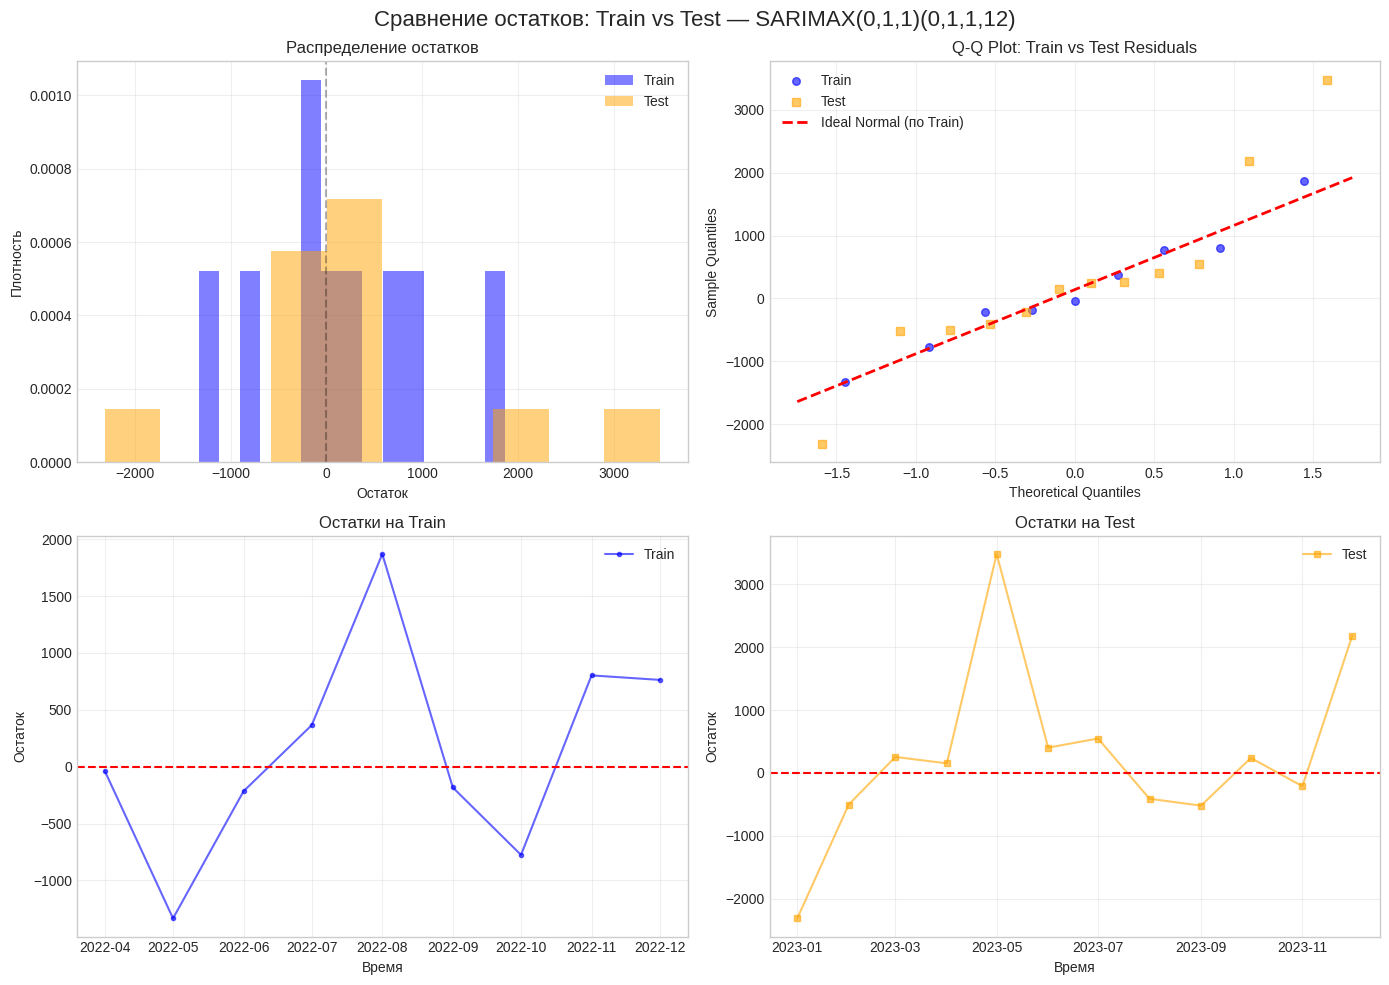

In [44]:
def get_results(model, is_sarimax, exog_test=None):
    burn = getattr(model, "loglikelihood_burn", 0) or 0
    train_resid = model.resid.iloc[burn:].dropna()
    pred = model.get_forecast(steps=h, exog=exog_test).predicted_mean if is_sarimax else model.get_forecast(steps=h).predicted_mean
    test_resid = y_test - pred
    return {"residuals": train_resid}, {"residuals": test_resid}

def plot_residuals(train_results, test_results, title_suffix):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Сравнение остатков: Train vs Test — {title_suffix}', fontsize=16)

    axes[0, 0].hist(train_results['residuals'], bins=15, alpha=0.5, label='Train', density=True, color='blue')
    axes[0, 0].hist(test_results['residuals'], bins=10, alpha=0.5, label='Test', density=True, color='orange')
    axes[0, 0].axvline(0, color='black', linestyle='--', alpha=0.3)
    axes[0, 0].set_xlabel('Остаток'); axes[0, 0].set_ylabel('Плотность')
    axes[0, 0].set_title('Распределение остатков')
    axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

    ax_qq = axes[0, 1]
    train_osm, train_osr = stats.probplot(train_results['residuals'], dist="norm", fit=False)
    ax_qq.scatter(train_osm, train_osr, alpha=0.6, label='Train', color='blue', s=30, marker='o')
    test_osm, test_osr = stats.probplot(test_results['residuals'], dist="norm", fit=False)
    ax_qq.scatter(test_osm, test_osr, alpha=0.6, label='Test', color='orange', s=30, marker='s')

    slope, intercept, _ = stats.probplot(train_results['residuals'], dist="norm", fit=True)[1]
    xline = np.array(ax_qq.get_xlim())
    ax_qq.plot(xline, intercept + slope * xline, 'r--', linewidth=2, label='Ideal Normal (по Train)')

    ax_qq.set_title('Q-Q Plot: Train vs Test Residuals')
    ax_qq.set_xlabel('Theoretical Quantiles'); ax_qq.set_ylabel('Sample Quantiles')
    ax_qq.legend(); ax_qq.grid(True, alpha=0.3)

    axes[1, 0].plot(train_results['residuals'].index, train_results['residuals'].values,
                    alpha=0.6, label='Train', color='blue', marker='o', markersize=3)
    axes[1, 0].axhline(0, color='red', linestyle='--')
    axes[1, 0].set_xlabel('Время'); axes[1, 0].set_ylabel('Остаток')
    axes[1, 0].set_title('Остатки на Train')
    axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(test_results['residuals'].index, test_results['residuals'].values,
                    alpha=0.6, color='orange', label='Test', marker='s', markersize=4)
    axes[1, 1].axhline(0, color='red', linestyle='--')
    axes[1, 1].set_xlabel('Время'); axes[1, 1].set_ylabel('Остаток')
    axes[1, 1].set_title('Остатки на Test')
    axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

train_a, test_a = get_results(model_arima, is_sarimax=False)
plot_residuals(train_a, test_a, "ARIMA(12,1,12)")

train_s, test_s = get_results(model_sarimax, is_sarimax=True, exog_test=exog_test[["HolidayMonth"]])
plot_residuals(train_s, test_s, "SARIMAX(0,1,1)(0,1,1,12)")

- ARIMA
    1. Довольно симметрична от -3000 до 3000 на train и он равномерно заполнен, а вот test смещен влево за исключением двух столбцов. Возможно на тесте моделна тесте ь занижает прогноз в начале, а потом выбрасывает в конце
    2. На qq точки лежат вдоль линии (возможно модель переобучилась). А вот на тесте свдиг в минус, справа точка выброшена вверх
    3. Остатки на train хаотичны и похожи на белый шум, на тесте будто бы нет разброс большой, и явно выделяется какой-то паттерн сезонности

- SARIMA

    Данных маловато
    1. На train и test более компактен разброс, чем у ARIMA. На тесте выбросы с 2х сторон.
    2. qq показывает, что точки лежат плотнее, особенно в центральной чати. Есть отклонения 2х точек на тесте
    3. По остаткам не могу сказать точно, так как данных 9 штук, но видно что, есть какие-то два выброса

In [45]:
import seaborn as sns

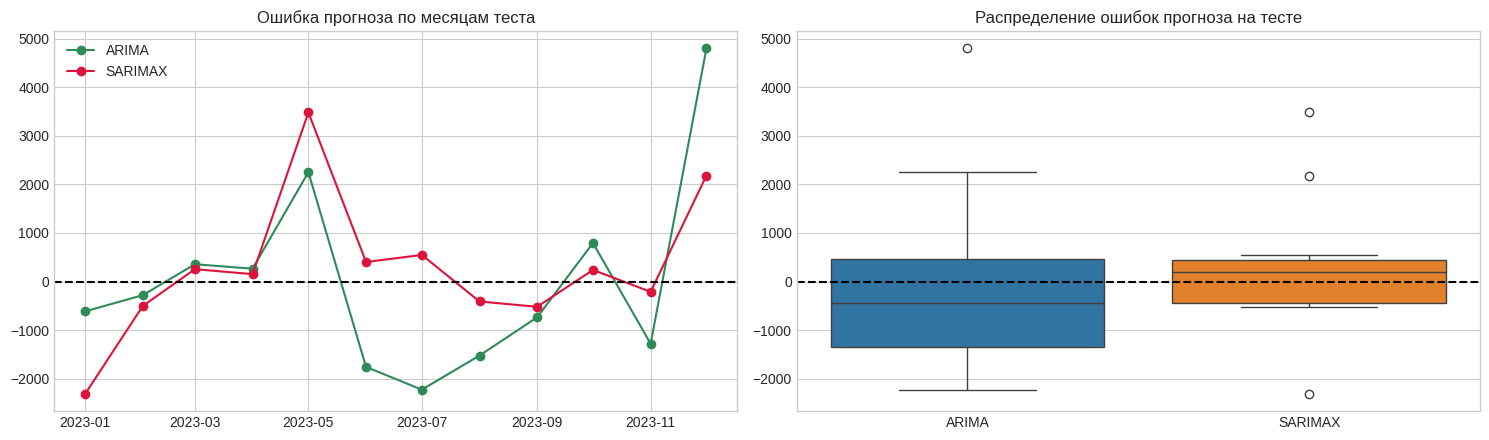

In [46]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
err_arima = y_test - pred_arima
err_sarimax = y_test - pred_sarimax

axs[0].plot(err_arima.index, err_arima, marker="o", color="seagreen", label="ARIMA")
axs[0].plot(err_sarimax.index, err_sarimax, marker="o", color="crimson", label="SARIMAX")
axs[0].axhline(0, color="k", ls="--"); axs[0].set_title("Ошибка прогноза по месяцам теста"); axs[0].legend()

sns.boxplot(data=pd.DataFrame({"ARIMA": err_arima.values, "SARIMAX": err_sarimax.values}), ax=axs[1])
axs[1].axhline(0, color="k", ls="--"); axs[1].set_title("Распределение ошибок прогноза на тесте")
plt.tight_layout(); plt.show()

Видно, что ошибки прогноза на тесте у ARIMA смещены вниз, модель склонна занижать прогноз, что было видно на графике окна предсказания. SARIMA семмитрична относительно нуля, коробка в пределах 500 и усы у нее очень близко расположены к коробке, что намного лучше относительно ARIMA, но модель ошиблась на 3х выбросах (на графике слева видно, что это 2023-01, 2023-05 и 2023-12)

## Итоговые выводы
Больше всего времени у меня занял первичных анализ данных и интерпретация результатов графиков, нежели построение моделей, хотя сложнее всего было понять, почему auto_arima предлагала d поставить равное 1, а не 0, так как ряд стационарный по тестам. Теперь думаю, надо ли было detrend делать на fft...

Помимо этого удивил пиксельных график вейвлет-преобразования, я почему-то ожидал там увидеть график с плавными деревьями.

### 1. EDA и частоты
- Сезонность сильныая, так как каждый декабрь у нас стабильно мощный взрыв продаж (праздники), а летом (июнь-июль) - провал. Фурье-анализ чётко подтвердил годовой цикл в 12 месяцев  и небольшую гармонику в 4 месяца. Вейвлеты тоже показали, что этот 12-месячный цикл стабильно шёл через все 4 года.
-  Декабрь критически важен для моделирования. А вот с промо-акциями странно: акция в январе 2021 и 2022 годов сработала замечательно (даже побила декабрьские рекорды), но в другие месяцы промо-кампании почти ничего не дали.
- ADF и KPSS показали, что ряд стационарный. Это было бы знаком, что нам не обязательно было всё дифференцировать, но дальше в моделях я не ожидал, что он дифференцирование все же нужно.

### 2. Модели


- **По качеству прогноза (на 2023 год) выиграл SARIMAX:**
  - Ошибка MSE у него ниже почти в 1.8 раза, а коэффициент $R^2$ больше аж в 2 раза (у ARIMA $R^2$ совсем слабенький).
  - Прогноз ARIMA уходит в минусовые и экстремально низкие значения, которых у нас никогда не было. А вот SARIMAX выдал адекватный и аккуратный прогноз, отлично повторив сезонную волну.
  - Плюсом, SARIMAX не стал слепо повторять аномальный скачок продаж в мае 2023 года, следовательно, модель не переобучилась.
- **По сложности и лаконичности:**
  - SARIMAX намного проще, так как он оценивает всего 4 параметра, тогда как ARIMA(12, 1, 12) пытается настроить сразу 25 штук на коротком ряду.
  * По критериям AIC и BIC просто гигантский разрыв в пользу SARIMAX.

### 3. Остатки
- Остатки похожи на нормальные у обоих, автокорреляции в них нет, дисперсия постоянна (почти). Но у SARIMAX из-за сезонного дифференцирования осталось всего 9 точек для анализа остатков на обучении.
- Зато на графиках ошибок теста всё встало на свои места: ошибки ARIMA сильно съехали вниз (модель постоянно занижает прогноз). У SARIMAX же ошибки красиво и симметрично группируются около нуля, хотя модель всё же промахнулась на трёх резких пиках (январь, май и декабрь 2023).